# 05. Total-return sensitivity (banks only)

**Purpose.** The main results use the split-adjusted `close`, which ignores dividends. This notebook repeats them on `adj_close` (split- and dividend-adjusted), so it shows how much the conclusions depend on leaving dividends out. This is metric M10 in `metric_definitions.md` (plan item 6). Every result is shown next to the price-return result, with the difference.

**What is repeated** (same code and settings as notebooks 02 and 03):
- **M2, M3, M4, M6, M9:** cumulative return, annualized return, volatility, Sharpe ratio and maximum drawdown, for the full period and each regime.
- **M6 intervals:** block-bootstrap interval for the Sharpe ratio (block 10 days, 10,000 resamples, the same seed as notebook 02).
- **M7 and H1:** CAPM beta, alpha, R-squared and the test of `beta = 1` (HC3 errors).
- **H2:** R-squared by regime with bootstrap intervals for the differences between regimes.
- **M8:** Dimson beta.

**How to run.** Select the project `.venv` as the kernel, then use *Restart* and *Run All*. The notebook asks for the PostgreSQL user and password at the first data cell. It only reads from the database. The bootstrap steps take roughly a minute. Tables are saved as CSV files in `reports/` (ignored by git).

**Read these before using the numbers.**
- The IHSG has no dividend adjustment in this data (its adjusted close equals its close, checked below). It is used unchanged as the market, so on the adjusted basis a bank's total return is compared with an index price return. This is a sensitivity, not a like-for-like comparison with the index. Because of that mismatch, expect alpha to move more than beta.
- `adj_close` from yfinance is not assumed to be a complete total-return series in every case. The adjustment was checked arithmetically earlier (expected factor = 1 - dividend / previous close).
- The Stub (from 20 May 2026) is shown for the summary table only. No interval or CAPM is computed for it.
- Everything is in-sample and descriptive.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
try:
    import db_access
    import metrics
    import statsmodels.api as sm
except ImportError as exc:
    raise ImportError(
        f"{exc}\nThis kernel is {sys.executable}. Select the project .venv kernel "
        "(top right of the notebook, Select Kernel > Python Environments > .venv), then Restart and Run All."
    ) from exc

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("project root:", ROOT)

project root: d:\Data Analyst\Portfolio


## 1. Load the data

Two reads, both `SELECT` only. Prices (both `close` and `adj_close`) rebuild the returns in Python; the SQL view is used to cross-check the adjusted returns and for the policy rate.

In [2]:
conn = db_access.connect()
try:
    prices = db_access.load_prices(conn)
    sql = db_access.load_excess_returns(conn)
finally:
    conn.close()

print("prices rows:", len(prices), "| SQL view rows:", len(sql))

prices rows: 5536 | SQL view rows: 5524


## 2. Settings and helpers

The bootstrap settings and seeds are the same as in notebooks 02 and 03, so the price-basis numbers in this notebook reproduce those results exactly (this is checked against the saved CSV files near the end).

In [3]:
BANKS = ["BBCA", "BBRI", "BMRI"]
MARKET = "IHSG"
TICKERS = BANKS + [MARKET]
FIRST_RETURN_DAY = pd.Timestamp("2021-01-04")
EXPECTED_DAYS = 1381
REGIME_DAYS = {"R1": 399, "R2": 499, "R3": 393, "Stub": 90}
PERIODS = ["Full", "R1", "R2", "R3"]            # periods with intervals and regressions (no Stub)
PAIRS = [("R1", "R2"), ("R2", "R3"), ("R1", "R3")]

N_BOOT = 10_000
BLOCK = 10
SEED = 20260101
LEVEL = 0.95
RET_TOL = 1e-12

COLORS = {"BBCA": "#2a78d6", "BBRI": "#eb6834", "BMRI": "#1baf7a", "IHSG": "#52514e"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d3"

results = []


def check(name, ok, detail=""):
    results.append(bool(ok))
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  [{detail}]" if detail else ""))


def tidy(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)

## 3. Returns on both bases

`price` uses `close` (the primary series). `adj` uses `adj_close`. Both go through the same function, the same risk-free rate (policy rate / 100 / 252) and the same regime labels. The checks confirm the adjusted returns match the SQL view and that the IHSG's adjusted close equals its close.

In [4]:
close = db_access.to_wide(prices, "close")[TICKERS]
adj = db_access.to_wide(prices, "adj_close")[TICKERS]
rate = sql.drop_duplicates("trade_date").set_index("trade_date")["rate_pct"].sort_index()
rf = metrics.daily_risk_free(rate)

ret_close = metrics.simple_returns(close, FIRST_RETURN_DAY)
ret_adj = metrics.simple_returns(adj, FIRST_RETURN_DAY)
BASES = {
    "price": {"px": close, "ret": ret_close, "excess": metrics.excess_return(ret_close, rf)},
    "adj": {"px": adj, "ret": ret_adj, "excess": metrics.excess_return(ret_adj, rf)},
}

labels = metrics.assign_regime(ret_close.index)
period_days = {"Full": ret_close.index}
period_days.update({name: ret_close.index[labels == name] for name in REGIME_DAYS})

sql_ret_adj = db_access.to_wide(sql, "ret_adj")[TICKERS]
sql_excess_adj = db_access.to_wide(sql, "excess_adj")[TICKERS]
check(f"{EXPECTED_DAYS} return days, no missing values on either basis",
      len(ret_close) == EXPECTED_DAYS and not ret_adj.isna().any().any() and not BASES["adj"]["excess"].isna().any().any())
check("adjusted returns equal the SQL view (ret_adj)", ret_adj.index.equals(sql_ret_adj.index)
      and (ret_adj - sql_ret_adj).abs().max().max() < RET_TOL)
check("adjusted excess returns equal the SQL view (excess_adj)", (BASES["adj"]["excess"] - sql_excess_adj).abs().max().max() < RET_TOL)
check("IHSG adjusted close equals its close (no dividends)", (ret_adj[MARKET] - ret_close[MARKET]).abs().max() < RET_TOL)
check("regime day counts", all(len(period_days[r]) == n for r, n in REGIME_DAYS.items()), str(REGIME_DAYS))

PASS  1381 return days, no missing values on either basis
PASS  adjusted returns equal the SQL view (ret_adj)
PASS  adjusted excess returns equal the SQL view (excess_adj)
PASS  IHSG adjusted close equals its close (no dividends)
PASS  regime day counts  [{'R1': 399, 'R2': 499, 'R3': 393, 'Stub': 90}]


## 4. Where the dividends are

Adjusted and price returns differ only on ex-dividend days, when the price drops by about the dividend. The table counts, for each bank, the days on which the two returns differ by more than 0.001 percentage points, and the size of the largest gap. The validation recorded 13 dividend events for BBCA, 10 for BBRI and 8 for BMRI over the whole download; events before 2021-01-04 fall outside the return window, so the counts here can be a little lower. This table is informational.

In [5]:
gap = (ret_adj[BANKS] - ret_close[BANKS])
div_days = pd.DataFrame({
    "ex_dividend_days": (gap.abs() > 1e-5).sum(),
    "largest_gap_pct_points": (100 * gap.abs().max()).round(3),
    "mean_gap_on_those_days_pct": [round(100 * gap[t][gap[t].abs() > 1e-5].mean(), 3) for t in BANKS],
})
div_days

,ex_dividend_days,largest_gap_pct_points,mean_gap_on_those_days_pct
ticker,,,
BBCA,13,4.214,1.338
BBRI,10,6.149,3.598
BMRI,8,9.370,4.824


## 5. M2, M3, M4, M6 and M9 side by side

For each bank and period: the figure on the price basis, on the adjusted basis, and the difference (adjusted minus price). The annualized return is calendar-time (`(1 + CR) ^ (365.25 / D) - 1`), not shown for the Stub. Maximum drawdown uses the price path from the close before the first return day, so the running maximum starts at the buy price. Since adjusted returns equal price returns on non-dividend days, volatility should barely move, and cumulative and annualized returns should rise by roughly the dividends received.

In [6]:
def summarize(b):
    px, r, e = b["px"], b["ret"], b["excess"]
    rows = []
    for period, days in period_days.items():
        start = px.index[px.index.get_loc(days[0]) - 1]
        calendar_days = (days[-1] - start).days
        for t in BANKS:
            cum = float(metrics.cumulative_return(r.loc[days, t]))
            rows.append({
                "period": period, "ticker": t, "n_days": len(days),
                "cum_return_pct": 100 * cum,
                "ann_return_pct": 100 * metrics.annualized_return(cum, calendar_days) if period != "Stub" else np.nan,
                "ann_vol_pct": 100 * metrics.annualized_volatility(r.loc[days, t]),
                "sharpe": metrics.sharpe_ratio(e.loc[days, t]),
                "mdd_pct": 100 * metrics.max_drawdown(px[t].loc[start:days[-1]])["mdd"],
            })
    return pd.DataFrame(rows).set_index(["period", "ticker"])


S = {basis: summarize(b) for basis, b in BASES.items()}
SUMMARY_COLS = ["cum_return_pct", "ann_return_pct", "ann_vol_pct", "sharpe", "mdd_pct"]
summary_cmp = pd.concat({m: pd.DataFrame({"price": S["price"][m], "adj": S["adj"][m], "diff": S["adj"][m] - S["price"][m]})
                         for m in SUMMARY_COLS}, axis=1)
summary_cmp.round(2)

cum_return_pct               ann_return_pct              ann_vol_pct              sharpe             mdd_pct             
                       price    adj   diff          price    adj  diff       price    adj  diff  price   adj  diff   price    adj  diff
period ticker                                                                                                                          
Full   BBCA           -10.27   6.95  17.21          -1.87   1.18  3.04       25.26  25.15 -0.11  -0.15 -0.02  0.13  -55.71 -51.79  3.92
       BBRI           -17.17  19.25  36.42          -3.22   3.11  6.33       29.69  29.41 -0.28  -0.13  0.09  0.22  -59.53 -50.35  9.18
       BMRI            26.80  88.39  61.59           4.22  11.64  7.43       30.71  30.13 -0.58   0.13  0.37  0.24  -50.20 -40.81  9.40
R1     BBCA            18.17  22.07   3.90          10.70  12.91  2.21       23.37  23.35 -0.03   0.42  0.50  0.09  -18.86 -17.72  1.14
       BBRI            12.64  19.93   7.29           7.51  11.70  4.18       29.34  29.25 -0.09   0.28  0.42  0.14  -24.13 -22.30  1.83
       BMRI            34.78  46.03  11.24          19.93  25.92  5.99       29.28  29.00 -0.28   0.67  0.85  0.18  -23.39 -20.78  2.61
R2     BBCA            31.25  38.15   6.90          14.02  16.87  2.85       19.64  19.80  0.16   0.51  0.64  0.13  -13.44 -13.10  0.34
       BBRI            24.12  38.97  14.85          10.99  17.21  6.22       24.43  24.15 -0.28   0.34  0.57  0.24  -35.94 -34.92  1.02
       BMRI            74.19  92.45  18.25          30.71  37.15  6.44       26.16  25.70 -0.46   0.99  1.19  0.21  -22.30 -20.69  1.61
R3     BBCA           -43.33 -38.32   5.01         -28.87 -25.16  3.71       28.71  28.27 -0.44  -1.31 -1.14  0.17  -46.58 -41.85  4.72
       BBRI           -42.64 -30.73  11.91         -28.35 -19.77  8.58       34.16  33.66 -0.50  -1.03 -0.69  0.34  -45.88 -37.17  8.72
       BMRI           -44.38 -32.01  12.37         -29.66 -20.66  9.00       35.72  34.68 -1.04  -1.02 -0.69  0.33  -45.64 -40.81  4.83
Stub   BBCA             2.10   2.82   0.72            NaN    NaN   NaN       40.38  40.39  0.01   0.20  0.25  0.05  -20.49 -20.49  0.00
       BBRI             3.29   3.29   0.00            NaN    NaN   NaN       36.21  36.21  0.00   0.27  0.27  0.00  -18.30 -18.30  0.00
       BMRI            -2.91  -1.41   1.50            NaN    NaN   NaN       36.07  35.94 -0.13  -0.21 -0.09  0.12  -15.33 -15.33  0.00

In [7]:
last, prior = close.index[-1], close.index[close.index.get_loc(FIRST_RETURN_DAY) - 1]
ratio = adj.loc[last, BANKS] / adj.loc[prior, BANKS] - 1
check("adjusted cumulative return equals the adjusted price ratio (full period)",
      (100 * ratio - S["adj"].xs("Full", level="period")["cum_return_pct"]).abs().max() < 1e-7)
check("adjusted cumulative return is at least the price return in every bank and period",
      (summary_cmp["cum_return_pct"]["diff"] > -1e-9).all())
no_dividend = [(p, t) for p in period_days for t in BANKS if not (gap.loc[period_days[p], t].abs() > 1e-5).any()]
check("periods with no ex-dividend day have identical returns and volatility on both bases",
      all(abs(summary_cmp.loc[k, ("ann_vol_pct", "diff")]) < 1e-9 and abs(summary_cmp.loc[k, ("cum_return_pct", "diff")]) < 1e-9
          for k in no_dividend), f"{len(no_dividend)} such period-bank pairs")
vol_gap = summary_cmp["ann_vol_pct"]["diff"]
print(f"largest volatility change: {vol_gap.abs().max():.3f} percentage points at {vol_gap.abs().idxmax()} "
      "(an ex-dividend day with a large price drop removes a large daily move from the adjusted series)")

PASS  adjusted cumulative return equals the adjusted price ratio (full period)
PASS  adjusted cumulative return is at least the price return in every bank and period
PASS  periods with no ex-dividend day have identical returns and volatility on both bases  [1 such period-bank pairs]
largest volatility change: 1.038 percentage points at ('R3', 'BMRI') (an ex-dividend day with a large price drop removes a large daily move from the adjusted series)


## 6. M6: Sharpe ratio and its uncertainty

Sharpe ratio with its 95% block-bootstrap interval on both bases (the Stub is excluded). Same resampled dates for every bank in a period, and the same seed as notebook 02, so the price-basis column reproduces that result. In the chart the bank's colour is fixed, a filled circle is the price basis and an open diamond is the adjusted basis.

In [8]:
rows = []
for period in PERIODS:
    days = period_days[period]
    for t in BANKS:
        row = {"period": period, "ticker": t}
        for basis, b in BASES.items():
            e = b["excess"].loc[days, t]
            low, high, _ = metrics.bootstrap_sharpe_ci(e, N_BOOT, BLOCK, SEED, LEVEL)
            row[f"sharpe_{basis}"], row[f"low_{basis}"], row[f"high_{basis}"] = metrics.sharpe_ratio(e), low, high
        row["sharpe_diff"] = row["sharpe_adj"] - row["sharpe_price"]
        rows.append(row)
sharpe_cmp = pd.DataFrame(rows).set_index(["period", "ticker"])
sharpe_cmp.round(3)

sharpe_price  low_price  high_price  sharpe_adj  low_adj  high_adj  sharpe_diff
period ticker                                                                                 
Full   BBCA          -0.148     -0.835       0.522      -0.023   -0.697     0.643        0.126
       BBRI          -0.134     -0.832       0.585       0.088   -0.624     0.821        0.222
       BMRI           0.133     -0.545       0.829       0.370   -0.328     1.081        0.236
R1     BBCA           0.417     -0.821       1.715       0.505   -0.720     1.788        0.088
       BBRI           0.282     -0.997       1.600       0.417   -0.862     1.717        0.135
       BMRI           0.669     -0.598       1.988       0.847   -0.416     2.170        0.178
R2     BBCA           0.508     -0.473       1.518       0.636   -0.342     1.646        0.128
       BBRI           0.336     -1.050       1.745       0.574   -0.848     1.999        0.237
       BMRI           0.986     -0.147       2.176       1.195    0.048     2.386        0.209
R3     BBCA          -1.309     -2.545      -0.041      -1.142   -2.390     0.120        0.167
       BBRI          -1.028     -2.366       0.234      -0.689   -2.050     0.602        0.338
       BMRI          -1.022     -2.349       0.239      -0.693   -2.091     0.641        0.329

PASS  each bootstrap interval contains its Sharpe ratio on both bases
PASS  the adjusted Sharpe ratio is not lower than the price Sharpe ratio (within 0.01)  [smallest difference 0.0881]


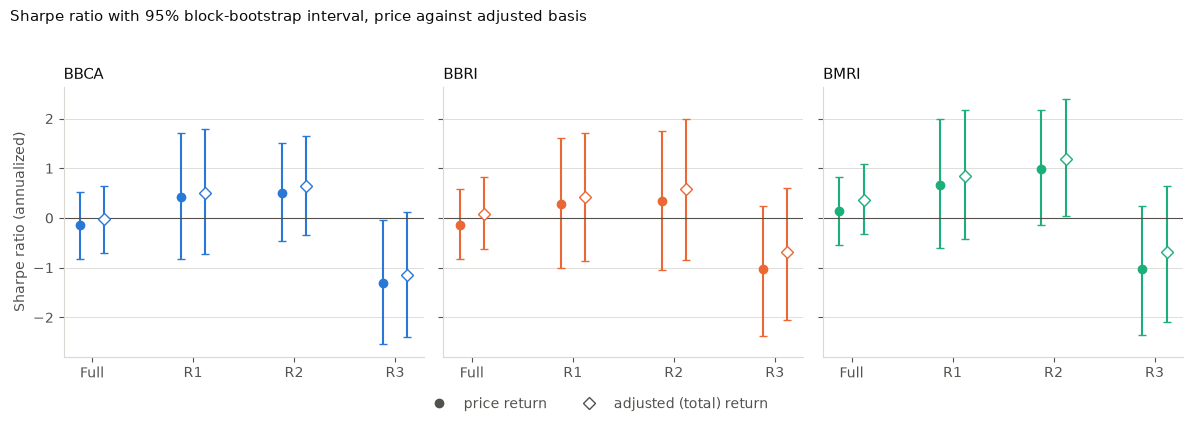

In [9]:
check("each bootstrap interval contains its Sharpe ratio on both bases",
      all(sharpe_cmp[f"low_{b}"].lt(sharpe_cmp[f"sharpe_{b}"]).all() and sharpe_cmp[f"high_{b}"].gt(sharpe_cmp[f"sharpe_{b}"]).all()
          for b in BASES))
check("the adjusted Sharpe ratio is not lower than the price Sharpe ratio (within 0.01)", (sharpe_cmp["sharpe_diff"] > -0.01).all(),
      f"smallest difference {sharpe_cmp['sharpe_diff'].min():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for ax, t in zip(axes, BANKS):
    for k, (basis, marker, filled) in enumerate((("price", "o", True), ("adj", "D", False))):
        x = np.arange(len(PERIODS)) + (k - 0.5) * 0.24
        sr = np.array([sharpe_cmp.loc[(p, t), f"sharpe_{basis}"] for p in PERIODS])
        lo = np.array([sharpe_cmp.loc[(p, t), f"low_{basis}"] for p in PERIODS])
        hi = np.array([sharpe_cmp.loc[(p, t), f"high_{basis}"] for p in PERIODS])
        ax.errorbar(x, sr, yerr=[sr - lo, hi - sr], fmt=marker, ms=6, lw=1.5, capsize=3, color=COLORS[t],
                    mfc=COLORS[t] if filled else "white", mec=COLORS[t])
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xticks(range(len(PERIODS)))
    ax.set_xticklabels(PERIODS)
    tidy(ax, t, "Sharpe ratio (annualized)" if t == BANKS[0] else "")
handles = [Line2D([], [], marker="o", color=MUTED, ls="", label="price return"),
           Line2D([], [], marker="D", mfc="white", mec=MUTED, color=MUTED, ls="", label="adjusted (total) return")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, labelcolor=MUTED)
fig.suptitle("Sharpe ratio with 95% block-bootstrap interval, price against adjusted basis", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
plt.show()

## 7. M7 and H1: CAPM on both bases

The same regression as notebook 03: bank excess return on the IHSG excess return, HC3 errors, t distribution, test of `beta = 1`. On the adjusted basis the bank return includes dividends and the market does not (see the note at the top), so the intercept (`alpha_ann_pct`) is expected to rise by about the dividend yield, while the slope should change little.

In [10]:
def fit_capm(y, x):
    return sm.OLS(y, sm.add_constant(x.rename("mkt"))).fit(cov_type="HC3", use_t=True)


rows = []
for basis, b in BASES.items():
    for period in PERIODS:
        days = period_days[period]
        for t in BANKS:
            res = fit_capm(b["excess"].loc[days, t], b["excess"].loc[days, MARKET])
            rows.append({"basis": basis, "period": period, "ticker": t,
                         "alpha_ann_pct": 100 * 252 * res.params["const"], "beta": res.params["mkt"], "beta_se": res.bse["mkt"],
                         "p_vs_1": float(np.squeeze(res.t_test("mkt = 1").pvalue)), "r2": res.rsquared})
capm_long = pd.DataFrame(rows)
cp, ca = (capm_long[capm_long["basis"] == k].set_index(["period", "ticker"]) for k in ("price", "adj"))
capm_cmp = pd.concat({m: pd.DataFrame({"price": cp[m], "adj": ca[m], "diff": ca[m] - cp[m]})
                      for m in ("alpha_ann_pct", "beta", "beta_se", "p_vs_1", "r2")}, axis=1)
capm_cmp.round(4)

alpha_ann_pct                      beta                 beta_se                  p_vs_1                      r2                
                      price      adj     diff   price     adj    diff   price     adj    diff   price     adj    diff   price     adj    diff
period ticker                                                                                                                                
Full   BBCA         -0.6595   2.5121   3.1716  0.9365  0.9358 -0.0007  0.0475  0.0473 -0.0003  0.1816  0.1741 -0.0074  0.3769  0.3795  0.0026
       BBRI         -0.2329   6.3390   6.5720  1.1404  1.1425  0.0021  0.0488  0.0486 -0.0002  0.0041  0.0035 -0.0007  0.4045  0.4138  0.0093
       BMRI          7.9450  14.9874   7.0425  1.1693  1.1694  0.0000  0.0526  0.0511 -0.0015  0.0013  0.0009 -0.0004  0.3973  0.4128  0.0155
R1     BBCA          0.8982   2.8946   1.9964  1.0566  1.0625  0.0059  0.0882  0.0880 -0.0002  0.5214  0.4782 -0.0432  0.3951  0.4005  0.0054
       BBRI         -2.9240   0.9839   3.9079  1.3380  1.3411  0.0031  0.0896  0.0895 -0.0001  0.0002  0.0002 -0.0000  0.4021  0.4065  0.0045
       BMRI          8.5714  13.7015   5.1300  1.3168  1.2990 -0.0178  0.0980  0.0979 -0.0001  0.0013  0.0024  0.0011  0.3909  0.3879 -0.0030
R2     BBCA         10.1657  12.7886   2.6229  0.9550  0.9695  0.0145  0.0774  0.0782  0.0008  0.5616  0.6969  0.1353  0.2763  0.2801  0.0038
       BBRI          8.4854  14.1327   5.6473  1.3557  1.3785  0.0228  0.0933  0.0909 -0.0024  0.0002  0.0000 -0.0001  0.3597  0.3805  0.0208
       BMRI         26.0745  30.9858   4.9113  1.4452  1.4262 -0.0189  0.1052  0.1031 -0.0021  0.0000  0.0000  0.0000  0.3564  0.3597  0.0033
R3     BBCA        -24.1644 -19.0058   5.1587  0.8242  0.8157 -0.0084  0.0790  0.0783 -0.0008  0.0267  0.0191 -0.0076  0.3691  0.3729  0.0038
       BBRI        -18.2087  -6.3564  11.8523  1.0379  1.0343 -0.0036  0.0851  0.0846 -0.0005  0.6563  0.6852  0.0289  0.4135  0.4230  0.0095
       BMRI        -19.2556  -6.5226  12.7330  1.0598  1.0755  0.0157  0.0904  0.0868 -0.0035  0.5088  0.3852 -0.1236  0.3944  0.4308  0.0365

In [11]:
check("the market is the same series on both bases, so the bank betas are comparable",
      (BASES["adj"]["excess"][MARKET] - BASES["price"]["excess"][MARKET]).abs().max() < RET_TOL)
check("the adjusted alpha is at least the price alpha (dividends add return)", (capm_cmp["alpha_ann_pct"]["diff"] > -1e-9).all())
print("largest change in beta:", round(capm_cmp["beta"]["diff"].abs().max(), 4),
      "| largest change in R-squared:", round(capm_cmp["r2"]["diff"].abs().max(), 4))

PASS  the market is the same series on both bases, so the bank betas are comparable
PASS  the adjusted alpha is at least the price alpha (dividends add return)
largest change in beta: 0.0228 | largest change in R-squared: 0.0365


## 8. H2: R-squared by regime on both bases

R-squared with a block-bootstrap interval (block 10) for each period, and the differences between regimes. The resampled dates are generated once per period and used for both bases and all banks, with the same seeds as notebook 03.

In [12]:
tail = (1 - LEVEL) / 2
boot = {}
for k, period in enumerate(PERIODS):
    days = period_days[period]
    idx = metrics.stationary_bootstrap_indices(len(days), N_BOOT, BLOCK, SEED + k)
    for basis, b in BASES.items():
        for t in BANKS:
            boot[(basis, period, t)] = metrics.r2_from_indices(b["excess"].loc[days, t], b["excess"].loc[days, MARKET], idx)

rows = []
for period in PERIODS:
    for t in BANKS:
        row = {"period": period, "ticker": t}
        for basis in BASES:
            low, high = np.quantile(boot[(basis, period, t)], [tail, 1 - tail])
            row[f"r2_{basis}"] = capm_long[(capm_long["basis"] == basis) & (capm_long["period"] == period)
                                           & (capm_long["ticker"] == t)]["r2"].iloc[0]
            row[f"low_{basis}"], row[f"high_{basis}"] = low, high
        rows.append(row)
r2_cmp = pd.DataFrame(rows).set_index(["period", "ticker"])

rows = []
for t in BANKS:
    for a, c in PAIRS:
        row = {"ticker": t, "pair": f"{a} - {c}"}
        for basis in BASES:
            d = boot[(basis, a, t)] - boot[(basis, c, t)]
            low, high = np.quantile(d, [tail, 1 - tail])
            row[f"diff_{basis}"] = r2_cmp.loc[(a, t), f"r2_{basis}"] - r2_cmp.loc[(c, t), f"r2_{basis}"]
            row[f"low_{basis}"], row[f"high_{basis}"] = low, high
            row[f"excludes_0_{basis}"] = bool(low > 0 or high < 0)
        rows.append(row)
r2_diff_cmp = pd.DataFrame(rows).set_index(["ticker", "pair"])
print(r2_cmp.round(3).to_string())
print()
print(r2_diff_cmp.round(3).to_string())

               r2_price  low_price  high_price  r2_adj  low_adj  high_adj
period ticker                                                            
Full   BBCA       0.377      0.301       0.450   0.380    0.304     0.453
       BBRI       0.405      0.338       0.468   0.414    0.347     0.478
       BMRI       0.397      0.336       0.457   0.413    0.347     0.479
R1     BBCA       0.395      0.291       0.496   0.400    0.296     0.503
       BBRI       0.402      0.301       0.493   0.407    0.304     0.497
       BMRI       0.391      0.317       0.462   0.388    0.316     0.457
R2     BBCA       0.276      0.209       0.339   0.280    0.212     0.344
       BBRI       0.360      0.283       0.431   0.380    0.306     0.449
       BMRI       0.356      0.287       0.422   0.360    0.288     0.428
R3     BBCA       0.369      0.247       0.504   0.373    0.250     0.510
       BBRI       0.413      0.296       0.525   0.423    0.302     0.540
       BMRI       0.394      0.284    

## 9. M8: Dimson beta on both bases

The sum of the slopes on the market return one day earlier, the same day and one day later (HC3 standard error of the sum), as in notebook 03.

In [13]:
KS = (-1, 0, 1)


def dimson_table(b):
    shifts = pd.DataFrame({f"k{k:+d}": b["excess"][MARKET].shift(-k) for k in KS})
    cols = list(shifts.columns)
    rows = []
    for period in PERIODS:
        days = period_days[period]
        for t in BANKS:
            d = pd.concat([b["excess"].loc[days, t].rename("y"), shifts.loc[days, cols]], axis=1).dropna()
            res = sm.OLS(d["y"], sm.add_constant(d[cols])).fit(cov_type="HC3", use_t=True)
            total = np.zeros((1, len(res.params)))
            total[0, 1:] = 1
            rows.append({"period": period, "ticker": t, "dimson_beta": float(res.params[cols].sum()),
                         "dimson_se": float(np.squeeze(res.t_test(total).sd))})
    return pd.DataFrame(rows).set_index(["period", "ticker"])


DT = {basis: dimson_table(b) for basis, b in BASES.items()}
dimson_cmp = pd.DataFrame({"dimson_price": DT["price"]["dimson_beta"], "dimson_adj": DT["adj"]["dimson_beta"],
                           "diff": DT["adj"]["dimson_beta"] - DT["price"]["dimson_beta"],
                           "capm_adj": ca["beta"], "se_adj": DT["adj"]["dimson_se"]})
dimson_cmp.round(4)

dimson_price  dimson_adj    diff  capm_adj  se_adj
period ticker                                                    
Full   BBCA          0.9213      0.9160 -0.0053    0.9358  0.0904
       BBRI          1.0925      1.1230  0.0306    1.1425  0.0784
       BMRI          1.1164      1.1124 -0.0040    1.1694  0.0851
R1     BBCA          0.8485      0.8502  0.0016    1.0625  0.1445
       BBRI          1.2769      1.2946  0.0177    1.3411  0.1599
       BMRI          1.1059      1.0775 -0.0285    1.2990  0.2009
R2     BBCA          0.9468      0.9641  0.0173    0.9695  0.1393
       BBRI          1.4727      1.4810  0.0083    1.3785  0.1558
       BMRI          1.2456      1.2798  0.0342    1.4262  0.2008
R3     BBCA          0.7070      0.6901 -0.0169    0.8157  0.1164
       BBRI          0.9509      1.0101  0.0592    1.0343  0.1310
       BMRI          1.1002      1.0962 -0.0041    1.0755  0.1304

## 10. Do the conclusions change?

Three kinds of verdict, each compared between the price and adjusted basis:
- **Sharpe:** does the 95% interval exclude 0?
- **H1:** is `beta = 1` rejected at the 5% level (HC3 p-value below 0.05)?
- **H2:** does the interval for the R-squared difference between two regimes exclude 0?

`changed` is True when the verdict differs between the two bases. The p-values are unadjusted, as in notebook 03.

In [14]:
rows = []
for (period, t), r in sharpe_cmp.iterrows():
    rows.append(("Sharpe interval excludes 0", period, t,
                 bool(r["low_price"] > 0 or r["high_price"] < 0), bool(r["low_adj"] > 0 or r["high_adj"] < 0)))
for (period, t), r in capm_cmp["p_vs_1"].iterrows():
    rows.append(("H1: beta = 1 rejected at 5%", period, t, bool(r["price"] < 0.05), bool(r["adj"] < 0.05)))
for (t, pair), r in r2_diff_cmp.iterrows():
    rows.append(("H2: R-squared difference excludes 0", pair, t, r["excludes_0_price"], r["excludes_0_adj"]))
verdicts = pd.DataFrame(rows, columns=["test", "period", "ticker", "price", "adj"])
verdicts["changed"] = verdicts["price"] != verdicts["adj"]

print(verdicts.groupby("test")["changed"].agg(total="size", changed="sum").to_string())
print()
print("verdicts that change between the price and adjusted basis:")
print(verdicts[verdicts["changed"]].to_string(index=False) if verdicts["changed"].any() else "none")

                                     total  changed
test                                               
H1: beta = 1 rejected at 5%             12        0
H2: R-squared difference excludes 0      9        0
Sharpe interval excludes 0              12        2

verdicts that change between the price and adjusted basis:
                      test period ticker  price   adj  changed
Sharpe interval excludes 0     R2   BMRI  False  True     True
Sharpe interval excludes 0     R3   BBCA   True False     True


## 11. Consistency with the earlier notebooks

The price-basis numbers in this notebook should be identical to the results saved by notebooks 02 and 03, because the code, settings and seeds are the same. If those CSV files exist in `reports/`, they are compared; a missing file is skipped.

In [15]:
reports = ROOT / "reports"


def compare_csv(name, fn):
    path = reports / name
    if path.exists():
        diff, label = fn(pd.read_csv(path))
        check(f"price basis equals the saved {name}", diff < label[0], label[1].format(diff))
    else:
        print(f"skipped  {name} not found (run the earlier notebook first)")


def summary_diff(old):
    old = old.set_index(["period", "ticker"])
    old = old[old.index.get_level_values("ticker").isin(BANKS)]
    new = S["price"].loc[old.index]
    d = max((new[c].round(2) - old[c]).abs().max() for c in SUMMARY_COLS)
    return d, (0.0051, "max abs diff {:.4f} (the saved table is rounded to 2 decimals)")


def sharpe_boot_diff(old):
    old = old.set_index(["period", "ticker"])
    old = old[old.index.get_level_values("ticker").isin(BANKS) & old.index.get_level_values("period").isin(PERIODS)]
    new = sharpe_cmp.loc[old.index]
    return max((new["low_price"] - old["ci_low_b10"]).abs().max(), (new["high_price"] - old["ci_high_b10"]).abs().max()), (1e-9, "max abs diff {:.2e}")


def capm_diff(old):
    old = old.set_index(["period", "ticker"])
    new = cp.loc[old.index]
    return max((new[c] - old[c]).abs().max() for c in ("beta", "r2", "p_vs_1")), (1e-9, "max abs diff {:.2e}")


def r2_boot_diff(old):
    old = old.set_index(["period", "ticker"])
    new = r2_cmp.loc[old.index]
    return max((new["low_price"] - old["ci_low_b10"]).abs().max(), (new["high_price"] - old["ci_high_b10"]).abs().max()), (1e-9, "max abs diff {:.2e}")


compare_csv("02_performance_summary.csv", summary_diff)
compare_csv("02_sharpe_bootstrap.csv", sharpe_boot_diff)
compare_csv("03_capm_regression.csv", capm_diff)
compare_csv("03_r2_bootstrap.csv", r2_boot_diff)

PASS  price basis equals the saved 02_performance_summary.csv  [max abs diff 0.0000 (the saved table is rounded to 2 decimals)]
PASS  price basis equals the saved 02_sharpe_bootstrap.csv  [max abs diff 8.33e-17]
PASS  price basis equals the saved 03_capm_regression.csv  [max abs diff 2.22e-16]
PASS  price basis equals the saved 03_r2_bootstrap.csv  [max abs diff 5.55e-17]


## 12. Summary and saved tables

Every check above must print PASS. The comparison tables are saved to `reports/` for the report.

In [16]:
out = ROOT / "reports"
out.mkdir(exist_ok=True)
div_days.to_csv(out / "05_ex_dividend_days.csv")
summary_cmp.to_csv(out / "05_summary_compare.csv")
sharpe_cmp.to_csv(out / "05_sharpe_compare.csv")
capm_cmp.to_csv(out / "05_capm_compare.csv")
r2_cmp.to_csv(out / "05_r2_compare.csv")
r2_diff_cmp.to_csv(out / "05_r2_differences_compare.csv")
dimson_cmp.to_csv(out / "05_dimson_compare.csv")
verdicts.to_csv(out / "05_verdicts.csv", index=False)

n_fail = results.count(False)
print(f"{len(results) - n_fail} passed, {n_fail} failed")
assert n_fail == 0, "At least one check failed. Investigate before using these tables."

16 passed, 0 failed
